In [1]:
!pip install -q paho-mqtt joblib scikit-learn

In [2]:
from google.colab import files

uploaded = files.upload()

Saving rgb_model (1).pkl to rgb_model (1).pkl


In [4]:
import joblib

model = joblib.load("rgb_model (1).pkl")

print("Model loaded successfully!")
print("Model type:", type(model))
print("Model classes:", model.classes_)
print("Input features:", model.n_features_in_)

Model loaded successfully!
Model type: <class 'sklearn.svm._classes.SVC'>
Model classes: [0 1 2]
Input features: 12288


In [6]:
import cv2
import numpy as np
import joblib

model = joblib.load("rgb_model (1).pkl")

def predict_color(frame):
    resized = cv2.resize(frame, (64, 64))
    features = resized.astype(np.float32).flatten() / 255.0

    prediction = model.predict([features])[0]

    class_names = {
        0: "Red",
        1: "Green",
        2: "Blue"
    }

    return class_names[prediction]

print("Smart Door Lock classifier ready!")

Smart Door Lock classifier ready!


Saving img1.jpeg to img1.jpeg
Image: img1.jpeg
Prediction: Blue


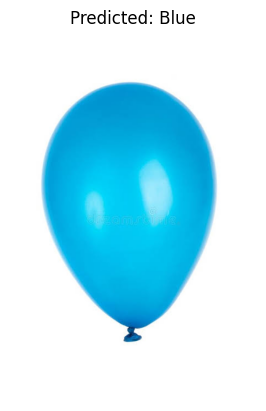

In [7]:
from google.colab import files
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded:
    image = cv2.imread(filename)

    if image is None:
        print(f"Could not read: {filename}")
        continue

    prediction = predict_color(image)

    print(f"Image: {filename}")
    print(f"Prediction: {prediction}")

    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"Predicted: {prediction}")
    plt.axis("off")
    plt.show()

Saving img6.jpeg to img6.jpeg
Image: img6.jpeg
Prediction: Green


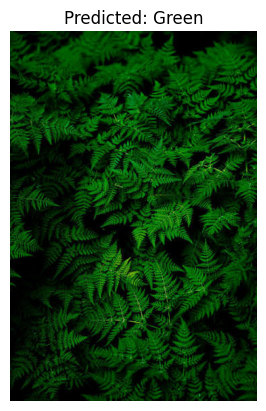

In [8]:
from google.colab import files
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded:
    image = cv2.imread(filename)

    if image is None:
        print(f"Could not read: {filename}")
        continue

    prediction = predict_color(image)

    print(f"Image: {filename}")
    print(f"Prediction: {prediction}")

    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"Predicted: {prediction}")
    plt.axis("off")
    plt.show()

Saving img1.jpg to img1.jpg
Image: img1.jpg
Prediction: Red


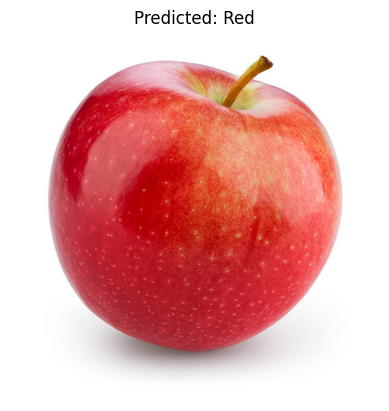

In [9]:
from google.colab import files
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded:
    image = cv2.imread(filename)

    if image is None:
        print(f"Could not read: {filename}")
        continue

    prediction = predict_color(image)

    print(f"Image: {filename}")
    print(f"Prediction: {prediction}")

    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"Predicted: {prediction}")
    plt.axis("off")
    plt.show()

In [10]:
def check_access(frame):
    prediction = predict_color(frame)

    if prediction == "Blue":
        return "open"

    elif prediction == "Green":
        return "deny"

    else:
        return "ignore"

print("Access decision logic ready!")

Access decision logic ready!


In [11]:

class AccessController:
    def __init__(self):
        self.last_decision = None
        self.consecutive_count = 0

    def process(self, frame):
        decision = check_access(frame)

        if decision == "ignore":
            self.last_decision = None
            self.consecutive_count = 0
            return "ignore"

        if decision == self.last_decision:
            self.consecutive_count += 1
        else:
            self.last_decision = decision
            self.consecutive_count = 1

        if self.consecutive_count >= 2:
            self.last_decision = None
            self.consecutive_count = 0
            return decision

        return "waiting"

controller = AccessController()

print("Two-frame confirmation ready!")


Two-frame confirmation ready!


In [12]:

import paho.mqtt.client as mqtt
import time

YOUR_NAME = "yashas113"
BROKER = "broker.emqx.io"
PORT = 1883
TOPIC = f"ssse/smartlock/{YOUR_NAME}/cmd"

def on_connect(client, userdata, flags, reason_code, properties=None):
    if reason_code == 0:
        print("Connected to MQTT broker!")
        print("Topic:", TOPIC)
    else:
        print("MQTT connection failed:", reason_code)

client = mqtt.Client(
    mqtt.CallbackAPIVersion.VERSION2
    if hasattr(mqtt, "CallbackAPIVersion")
    else mqtt.CallbackAPIVersion.VERSION1
)

client.on_connect = on_connect
client.connect(BROKER, PORT, 60)
client.loop_start()

time.sleep(2)

print("MQTT setup completed.")


Connected to MQTT broker!
Topic: ssse/smartlock/yashas113/cmd
MQTT setup completed.


In [13]:

def send_command(command):
    if command not in ["open", "deny"]:
        print("Invalid command:", command)
        return

    if not client.is_connected():
        print("MQTT client is disconnected!")
        return

    result = client.publish(TOPIC, command, qos=0)

    if result.rc == mqtt.MQTT_ERR_SUCCESS:
        print(f"Command published: {command}")
    else:
        print("Publish failed:", result.rc)

print("MQTT command function ready!")


MQTT command function ready!


In [15]:
send_command("open")

Command published: open


In [31]:

send_command("open")


Command published: open


In [46]:

import time

# Wait until the previous complaint interval is satisfied
time.sleep(3)

# Trigger the third complaint
send_command("deny")

# Wait briefly for the ESP32 to process it
time.sleep(0.5)

# Send OPEN during the lockout
send_command("open")


Command published: deny
Command published: open


In [48]:

import time

print("Starting lockout test...")

# Complaint 1
send_command("deny")
time.sleep(2.5)

# Complaint 2
send_command("deny")
time.sleep(2.5)

# Complaint 3
send_command("deny")
time.sleep(0.5)

# Test OPEN during lockout
send_command("open")

print("Lockout test commands sent.")


Starting lockout test...
Command published: deny
Command published: deny
Command published: deny
Command published: open
Lockout test commands sent.


In [50]:

import time

print("Starting Smart Door Lock test...")

send_command("deny")
time.sleep(4)

send_command("deny")
time.sleep(4)

send_command("deny")
time.sleep(1)

send_command("open")

print("Test commands sent.")


Starting Smart Door Lock test...
Command published: deny
Command published: deny
Command published: deny
Command published: open
Test commands sent.


In [51]:

def send_command(command):
    if command not in ["open", "deny"]:
        print("Invalid command:", command)
        return

    if not client.is_connected():
        print("MQTT disconnected. Reconnecting...")
        return

    try:
        info = client.publish(TOPIC, command, qos=1)

        info.wait_for_publish(timeout=5)

        if info.is_published():
            print(f"MQTT publish acknowledged: {command}")
        else:
            print("MQTT publish acknowledgement timed out.")

    except Exception as e:
        print("MQTT publishing error:", e)


In [53]:

send_command("deny")


MQTT publish acknowledged: deny


In [54]:

print("get_frame available:", "get_frame" in globals())
print("stop_camera available:", "stop_camera" in globals())
print("predict_color available:", "predict_color" in globals())
print("controller available:", "controller" in globals())
print("MQTT connected:", client.is_connected())


get_frame available: False
stop_camera available: False
predict_color available: True
controller available: True
MQTT connected: True


In [55]:

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import numpy as np
import cv2
import time

# Start webcam
def start_camera():

    display(Javascript("""
    async function startCamera() {
        const video = document.createElement('video');
        video.style.width = '480px';
        video.style.border = '3px solid green';
        video.autoplay = true;
        video.playsInline = true;

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        document.body.appendChild(video);
        window.smartLockVideo = video;

        const canvas = document.createElement('canvas');
        window.smartLockCanvas = canvas;
    }
    startCamera();
    """))

    time.sleep(2)
    print("Camera started!")

# Capture one frame
def get_frame():

    data = eval_js("""
    (function() {
        const video = window.smartLockVideo;
        const canvas = window.smartLockCanvas;

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(video, 0, 0);

        return canvas.toDataURL('image/jpeg');
    })()
    """)

    image_bytes = b64decode(data.split(',')[1])
    frame = cv2.imdecode(
        np.frombuffer(image_bytes, np.uint8),
        cv2.IMREAD_COLOR
    )

    return frame

# Stop webcam
def stop_camera():

    eval_js("""
    if (window.smartLockVideo) {
        window.smartLockVideo.srcObject.getTracks().forEach(
            track => track.stop()
        );
        window.smartLockVideo.remove();
    }
    """)

    print("Camera stopped!")

print("Webcam functions ready!")


Webcam functions ready!


In [58]:

start_camera()


<IPython.core.display.Javascript object>

Camera started!


In [61]:
import time
from google.colab.output import eval_js

print("SMART DOOR LOCK: CAMERA SYSTEM STARTED")
print("Blue  = Authorized visitor")
print("Green = Unauthorized visitor")
print("Red   = No action")
print("Two consecutive frames are required.")
print("--------------------------------------")

# Quick pre-flight check to verify if camera is active in browser
camera_ready = eval_js("typeof window.smartLockVideo !== 'undefined'")
if not camera_ready:
    print("WARNING: Camera stream is not active. Attempting to start the camera...")
    try:
        start_camera()
    except Exception as e:
        print("Could not automatically start camera. Please run start_camera() again and grant camera permissions.")

last_sent_decision = None
last_status = None

try:
    start_time = time.time()

    while time.time() - start_time < 60:
        # Ensure camera is globally ready before grabbing a frame
        if not eval_js("typeof window.smartLockVideo !== 'undefined'"):
            print("Waiting for camera stream to become active...")
            time.sleep(1)
            continue

        # Capture camera frame
        frame = get_frame()

        if frame is None:
            continue

        # Process using the existing two-frame controller
        decision = controller.process(frame)

        # Print status only when it changes
        if decision != last_status:
            print("Detection status:", decision)
            last_status = decision

        # Send each continuous detection only once
        if decision == "open" and last_sent_decision != "open":
            print("AUTHORIZED VISITOR CONFIRMED")
            send_command("open")
            last_sent_decision = "open"

        elif decision == "deny" and last_sent_decision != "deny":
            print("UNAUTHORIZED VISITOR CONFIRMED")
            send_command("deny")
            last_sent_decision = "deny"

        # Reset trigger when red/no-action is detected
        elif decision == "ignore":
            last_sent_decision = None

        time.sleep(0.2)

except KeyboardInterrupt:
    print("Camera detection interrupted.")

finally:
    stop_camera()
    print("Smart Door Lock camera system stopped.")

SMART DOOR LOCK: CAMERA SYSTEM STARTED
Blue  = Authorized visitor
Green = Unauthorized visitor
Red   = No action
Two consecutive frames are required.
--------------------------------------


<IPython.core.display.Javascript object>

Camera started!
Detection status: waiting
Detection status: open
AUTHORIZED VISITOR CONFIRMED
MQTT publish acknowledged: open
Detection status: waiting
Detection status: open
Detection status: waiting
Detection status: open
Detection status: waiting
Detection status: open
Detection status: waiting
Detection status: open
Detection status: waiting
Detection status: open
Detection status: waiting
Detection status: open
Detection status: waiting
Detection status: open
Detection status: waiting
Detection status: open
Detection status: waiting
Detection status: open
Detection status: waiting
Detection status: deny
UNAUTHORIZED VISITOR CONFIRMED
MQTT publish acknowledged: deny
Detection status: waiting
Detection status: deny
Detection status: waiting
Detection status: deny
Detection status: waiting
Detection status: deny
Detection status: waiting
Detection status: deny
Detection status: waiting
Detection status: open
AUTHORIZED VISITOR CONFIRMED
MQTT publish acknowledged: open
Detection statu

In [63]:

send_command("deny")


MQTT publish acknowledged: deny


In [64]:
send_command("deny")
time.sleep(2.5)

send_command("deny")
time.sleep(2.5)

send_command("deny")
time.sleep(0.5)

send_command("open")

MQTT publish acknowledged: deny
MQTT publish acknowledged: deny
MQTT publish acknowledged: deny
MQTT publish acknowledged: open


In [65]:
import time

print("Starting lockout verification...")

send_command("deny")
time.sleep(2.5)

send_command("deny")
time.sleep(2.5)

send_command("deny")
time.sleep(0.5)

send_command("open")

print("Lockout test commands sent.")

Starting lockout verification...
MQTT publish acknowledged: deny
MQTT publish acknowledged: deny
MQTT publish acknowledged: deny
MQTT publish acknowledged: open
Lockout test commands sent.


In [66]:
import time

send_command("deny")
time.sleep(5)

send_command("deny")
time.sleep(5)

send_command("deny")
time.sleep(1)

send_command("open")

MQTT publish acknowledged: deny
MQTT publish acknowledged: deny
MQTT publish acknowledged: deny
MQTT publish acknowledged: open
